Predicting Stock Market Prices	Design and implement a Decision Tree Regression model for predicting TSLA Close prices, followed by comprehensive visualization and interpretation of the decision paths in the tree structure to understand feature splits and decision rules.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

In [2]:
# 1. Load, sort chronologically, and deduplicate repeated trading dates
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').drop_duplicates(subset=['Date'], keep='last').reset_index(drop=True)

# 2. Leakage-free lagged & technical features (anchored strictly at t-1)
s_close = df['Close'].shift(1)
df['Close_Lag_1'] = df['Close'].shift(1)
df['Close_Lag_2'] = df['Close'].shift(2)
df['Close_Lag_5'] = df['Close'].shift(5)
df['Log_Return_Lag1'] = np.log(df['Close'].shift(1) / df['Close'].shift(2))
df['Volume_Lag1'] = df['Volume'].shift(1)

df['EMA_7'] = s_close.ewm(span=7, adjust=False).mean()
df['SMA_10'] = s_close.rolling(window=10).mean()
df['SMA_20'] = s_close.rolling(window=20).mean()

delta = s_close.diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
df['RSI_14'] = 100 - (100 / (1 + (avg_gain / avg_loss)))

ema12 = s_close.ewm(span=12, adjust=False).mean()
ema26 = s_close.ewm(span=26, adjust=False).mean()
df['MACD'] = ema12 - ema26
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

bb_mid = s_close.rolling(window=20).mean()
bb_std = s_close.rolling(window=20).std()
df['BB_Width'] = (4 * bb_std) / bb_mid
df['BB_PctB'] = (s_close - (bb_mid - 2 * bb_std)) / (4 * bb_std)

df_model = df.dropna().reset_index(drop=True)
feature_cols = [
    'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'EMA_7', 'SMA_10', 'SMA_20',
    'Log_Return_Lag1', 'RSI_14', 'MACD', 'MACD_Signal', 'MACD_Hist',
    'BB_Width', 'BB_PctB', 'Volume_Lag1'
]

# 3. Chronological 80/20 Train-Test Split (Tree models do not require feature scaling)
split_idx = int(len(df_model) * 0.80)
train_df = df_model.iloc[:split_idx].copy()
test_df = df_model.iloc[split_idx:].copy()

X_train, y_train = train_df[feature_cols], train_df['Close']
X_test, y_test = test_df[feature_cols], test_df['Close']

print(f"Dataset Ready -> Train: {len(train_df)} days | Test: {len(test_df)} days | Features: {len(feature_cols)}")

Dataset Ready -> Train: 60 days | Test: 15 days | Features: 14


In [3]:
# 1. Baseline Unconstrained Decision Tree (demonstrates memorization/overfitting risk)
dt_unconstrained = DecisionTreeRegressor(random_state=42)
dt_unconstrained.fit(X_train, y_train)

# 2. Hyperparameter Tuning & Cost-Complexity Pruning via Expanding-Window TimeSeriesSplit
param_grid = {
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_split': [2, 4, 6, 8],
    'min_samples_leaf': [1, 2, 3, 4],
    'ccp_alpha': [0.0, 0.05, 0.1, 0.5]
}

tscv = TimeSeriesSplit(n_splits=4)
grid_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error'
)
grid_search.fit(X_train, y_train)
best_dt = grid_search.best_estimator_

print(f"Optimal Hyperparameters: {grid_search.best_params_}\n")

# Compare Train vs. Test Performance
eval_rows = []
for name, model in [('Unconstrained Tree (Overfit)', dt_unconstrained), ('Tuned Pruned Tree (Best)', best_dt)]:
    tr_pred = model.predict(X_train)
    te_pred = model.predict(X_test)
    eval_rows.append({
        'Model': name,
        'Depth': model.get_depth(),
        'Leaves': model.get_n_leaves(),
        'Train_RMSE ($)': round(np.sqrt(mean_squared_error(y_train, tr_pred)), 4),
        'Train_R²': round(r2_score(y_train, tr_pred), 4),
        'Test_RMSE ($)': round(np.sqrt(mean_squared_error(y_test, te_pred)), 4),
        'Test_MAE ($)': round(mean_absolute_error(y_test, te_pred), 4),
        'Test_MAPE (%)': round(mean_absolute_percentage_error(y_test, te_pred) * 100, 2),
        'Test_R²': round(r2_score(y_test, te_pred), 4)
    })

print("--- Decision Tree Model Comparison ---")
print(pd.DataFrame(eval_rows).to_string(index=False))

Optimal Hyperparameters: {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 4}

--- Decision Tree Model Comparison ---
                       Model  Depth  Leaves  Train_RMSE ($)  Train_R²  Test_RMSE ($)  Test_MAE ($)  Test_MAPE (%)  Test_R²
Unconstrained Tree (Overfit)     10      60          0.0000    1.0000         5.5328        4.1707           1.04  -0.6332
    Tuned Pruned Tree (Best)      3       7          3.0925    0.9206         5.0577        4.2213           1.05  -0.3648


In [4]:
# 1. Print full human-readable IF-ELSE tree structure
print("--- Extracted Decision Tree Rules (Tuned Pruned Tree) ---")
print(export_text(best_dt, feature_names=feature_cols, decimals=2))

# 2. Trace exact root-to-leaf decision paths for specific out-of-sample test dates
def trace_decision_path(model, X_sample_df, dates_series, y_actual_series, sample_indices):
    tree_ = model.tree_
    feature_names = X_sample_df.columns
    node_indicator = model.decision_path(X_sample_df)
    leaf_ids = model.apply(X_sample_df)
    preds = model.predict(X_sample_df)

    for idx in sample_indices:
        date_str = str(dates_series.iloc[idx].date())
        actual_val = y_actual_series.iloc[idx]
        pred_val = preds[idx]
        node_index = node_indicator.indices[node_indicator.indptr[idx]:node_indicator.indptr[idx + 1]]

        print(f"\n[Test Date: {date_str}] Actual Close = ${actual_val:.2f} | Predicted Leaf Value = ${pred_val:.2f} (Error = ${actual_val - pred_val:+.2f})")
        for node_id in node_index:
            if leaf_ids[idx] == node_id:
                print(f"  -> Reached Leaf Node #{node_id} (n_samples={tree_.n_node_samples[node_id]}, prediction=${tree_.value[node_id][0][0]:.2f})")
            else:
                feat = feature_names[tree_.feature[node_id]]
                thresh = tree_.threshold[node_id]
                val = X_sample_df.iloc[idx][feat]
                sign = "<=" if val <= thresh else ">"
                print(f"  -> Node #{node_id}: {feat} ({val:.2f}) {sign} {thresh:.2f}")

print("--- Tracing Decision Paths on First, Middle & Final Test Days ---")
trace_decision_path(best_dt, X_test, test_df['Date'], y_test, sample_indices=[0, len(X_test)//2, len(X_test)-1])

--- Extracted Decision Tree Rules (Tuned Pruned Tree) ---
|--- Close_Lag_1 <= 387.49
|   |--- SMA_20 <= 376.51
|   |   |--- Close_Lag_2 <= 380.26
|   |   |   |--- value: [382.25]
|   |   |--- Close_Lag_2 >  380.26
|   |   |   |--- value: [378.53]
|   |--- SMA_20 >  376.51
|   |   |--- value: [386.23]
|--- Close_Lag_1 >  387.49
|   |--- Close_Lag_1 <= 403.92
|   |   |--- Close_Lag_5 <= 396.26
|   |   |   |--- value: [396.75]
|   |   |--- Close_Lag_5 >  396.26
|   |   |   |--- value: [402.27]
|   |--- Close_Lag_1 >  403.92
|   |   |--- Close_Lag_1 <= 409.90
|   |   |   |--- value: [407.56]
|   |   |--- Close_Lag_1 >  409.90
|   |   |   |--- value: [413.12]

--- Tracing Decision Paths on First, Middle & Final Test Days ---

[Test Date: 2025-04-24] Actual Close = $410.03 | Predicted Leaf Value = $407.56 (Error = $+2.47)
  -> Node #0: Close_Lag_1 (407.32) > 387.49
  -> Node #6: Close_Lag_1 (407.32) > 403.92
  -> Node #10: Close_Lag_1 (407.32) <= 409.90
  -> Reached Leaf Node #11 (n_samples=

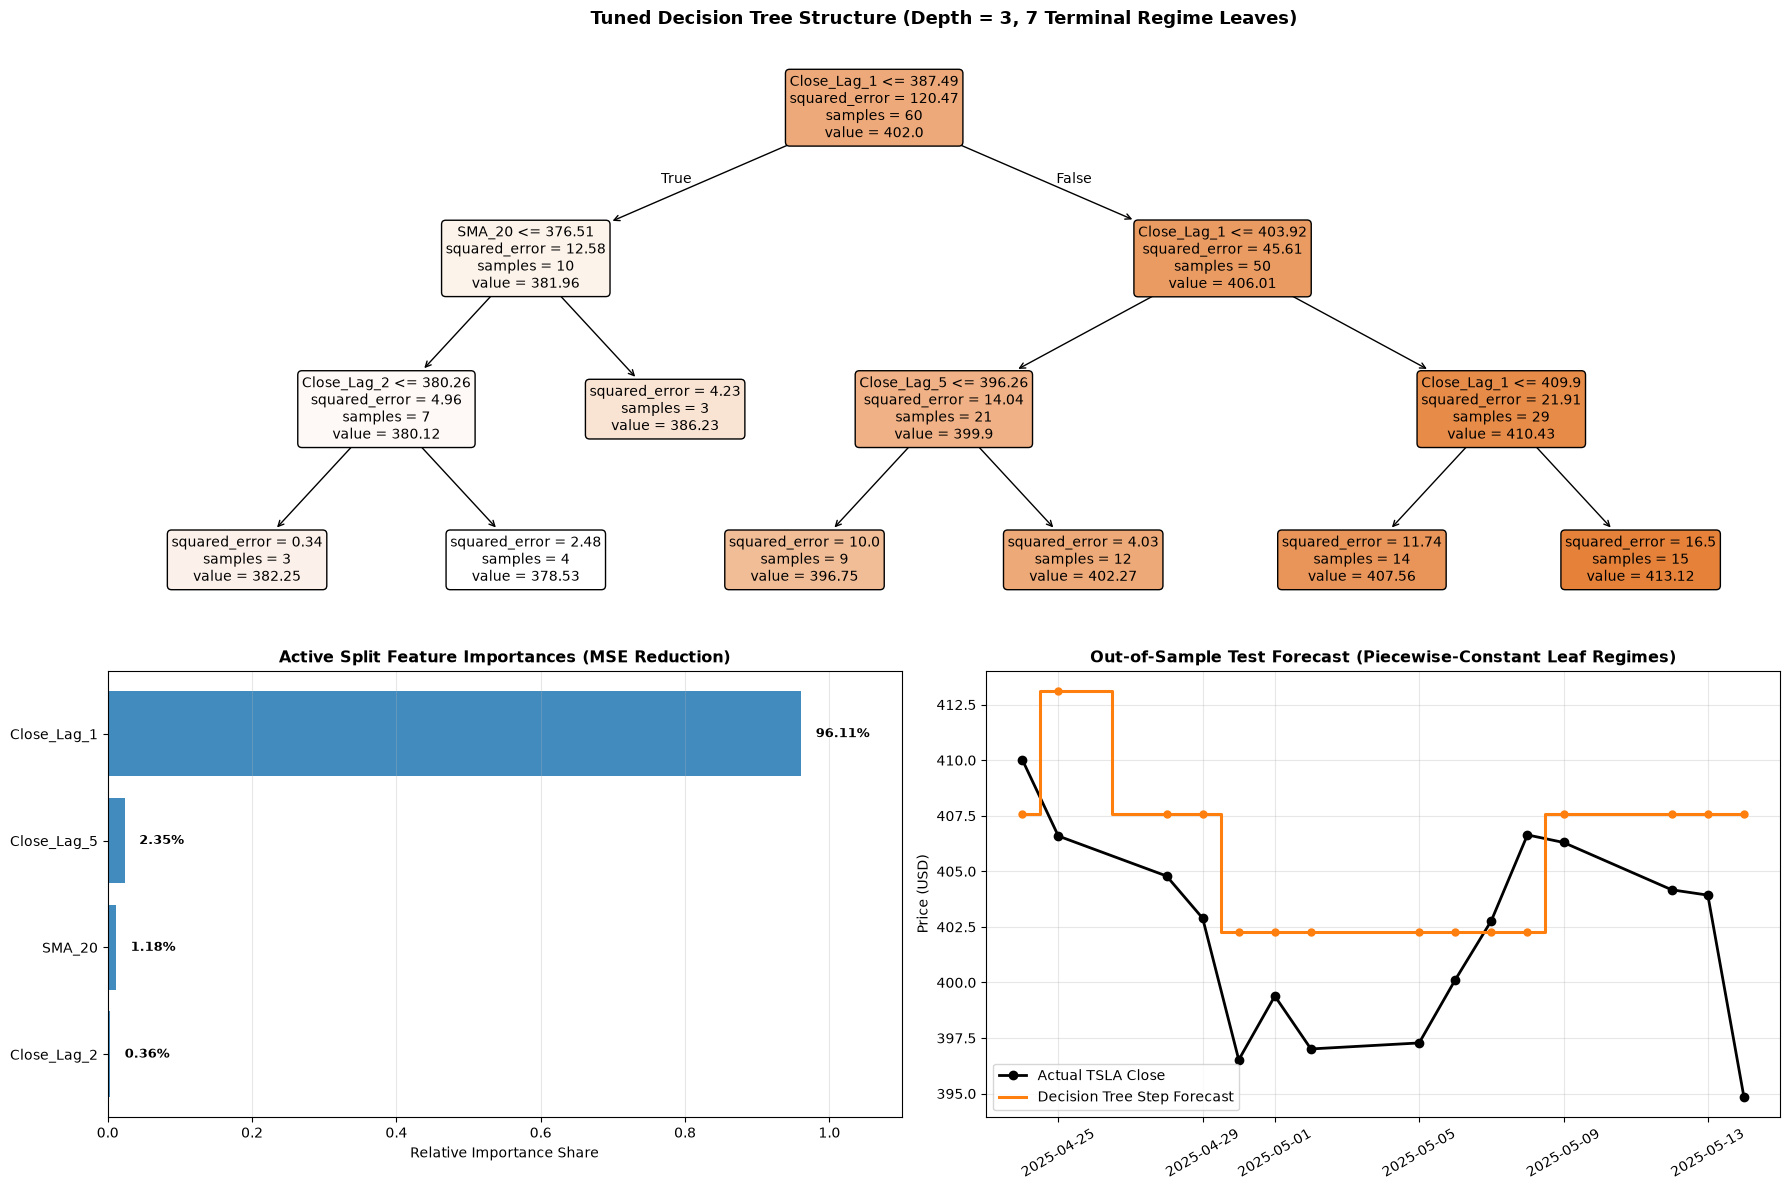

In [6]:
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(2, 2, height_ratios=[1.35, 1.0])

# Panel 1 (Top Full Width): Complete Graphical Decision Tree Diagram
ax_tree = fig.add_subplot(gs[0, :])
plot_tree(
    best_dt,
    feature_names=feature_cols,
    filled=True,
    rounded=True,
    fontsize=10,
    precision=2,
    ax=ax_tree
)
ax_tree.set_title('Tuned Decision Tree Structure (Depth = 3, 7 Terminal Regime Leaves)', fontsize=13, fontweight='bold')

# Panel 2 (Bottom Left): Gini / MSE Reduction Feature Importance
ax_imp = fig.add_subplot(gs[1, 0])
importances = pd.Series(best_dt.feature_importances_, index=feature_cols).sort_values(ascending=True)
active_imp = importances[importances > 0]
bars = ax_imp.barh(active_imp.index, active_imp.values, color='#1f77b4', alpha=0.85)
ax_imp.set_title('Active Split Feature Importances (MSE Reduction)', fontsize=11.5, fontweight='bold')
ax_imp.set_xlabel('Relative Importance Share')
ax_imp.set_xlim(0, 1.1)
ax_imp.grid(axis='x', alpha=0.3)
for bar in bars:
    ax_imp.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
                f"{bar.get_width()*100:.2f}%", va='center', fontsize=9.5, fontweight='bold')

# Panel 3 (Bottom Right): Out-of-Sample Piecewise-Constant Step Predictions
ax_pred = fig.add_subplot(gs[1, 1])
te_preds = best_dt.predict(X_test)
ax_pred.plot(test_df['Date'], y_test, color='black', marker='o', linewidth=2, label='Actual TSLA Close')
ax_pred.step(test_df['Date'], te_preds, where='mid', color='#ff7f0e', linewidth=2.2, label='Decision Tree Step Forecast')
ax_pred.plot(test_df['Date'], te_preds, 'o', color='#ff7f0e', markersize=5)
ax_pred.set_title('Out-of-Sample Test Forecast (Piecewise-Constant Leaf Regimes)', fontsize=11.5, fontweight='bold')
ax_pred.set_ylabel('Price (USD)')
ax_pred.tick_params(axis='x', rotation=30)
ax_pred.legend(loc='lower left')
ax_pred.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()